# Week 3 — Unsupervised Learning and Customer Clustering
## Bank Customer Segmentation using K-Means

**Goal:** Discover customer groups from customer profile and contact-history features. The target `y` and post-call `duration` are excluded from clustering so groups are not constructed using the answer or post-contact information.


In [13]:

import io, zipfile, urllib.request, warnings, os, json, math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
DATA_URL = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"

def extract_bank_full(zip_bytes):
    """Find bank-full.csv even when it is nested in an inner ZIP."""
    with zipfile.ZipFile(io.BytesIO(zip_bytes)) as zf:
        for name in zf.namelist():
            if Path(name).name.lower() == "bank-full.csv":
                return zf.read(name)
        for name in zf.namelist():
            if name.lower().endswith(".zip"):
                try:
                    found = extract_bank_full(zf.read(name))
                    if found:
                        return found
                except (zipfile.BadZipFile, KeyError):
                    pass
    return None

def load_bank_marketing():
    archive = urllib.request.urlopen(DATA_URL, timeout=60).read()
    csv_bytes = extract_bank_full(archive)
    if csv_bytes is None:
        raise FileNotFoundError("Could not find bank-full.csv in the official UCI archive.")
    data = pd.read_csv(io.BytesIO(csv_bytes), sep=";", keep_default_na=False)
    data.columns = [c.strip().lower() for c in data.columns]
    return data

df_raw = load_bank_marketing()
print("Dataset shape:", df_raw.shape)
display(df_raw.head())

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, RobustScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.decomposition import PCA


Dataset shape: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


## 1. Feature design and preparation

The analysis uses age, balance, current campaign contact count, days since previous contact, previous contact count, day of month, and a prior-contact indicator. Job, marital status, education, credit default, housing loan, personal loan, contact method, month, and previous campaign outcome are categorical. High-cardinality identifiers are not present. `pdays = -1` is transformed into an indicator plus a missing continuous `pdays_clean` field. Extreme numeric values are winsorized at the 1st and 99th percentiles for the clustering copy only; raw data is preserved.


In [14]:
seg = df_raw.copy()
for c in seg.select_dtypes(include="object").columns:
    seg[c] = seg[c].str.strip().str.lower()
seg["previously_contacted"] = (seg["pdays"] != -1).astype(int)
seg["pdays_clean"] = seg["pdays"].where(seg["pdays"] != -1, np.nan)

numeric = ["age","balance","campaign","pdays_clean","previous","day","previously_contacted"]
categorical = ["job","marital","education","default","housing","loan","contact","month","poutcome"]
X = seg[numeric + categorical].copy()

for col in ["age","balance","campaign","pdays_clean","previous","day"]:
    lo, hi = X[col].quantile([.01,.99])
    X[col] = X[col].clip(lo, hi)

num_pipe = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", RobustScaler())])
cat_pipe = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                     ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=True))])
prep = ColumnTransformer([("num", num_pipe, numeric), ("cat", cat_pipe, categorical)])
Xz = prep.fit_transform(X)
print("Encoded matrix:", Xz.shape)


Encoded matrix: (45211, 51)


## 2. Determine a practical number of segments

Evaluate k from 2 through 8 using inertia and silhouette score. Silhouette is calculated on a reproducible sample because calculating all pairwise distances for every row can be expensive. Do not select k only because it maximizes a single metric: very small clusters may be operationally unhelpful.


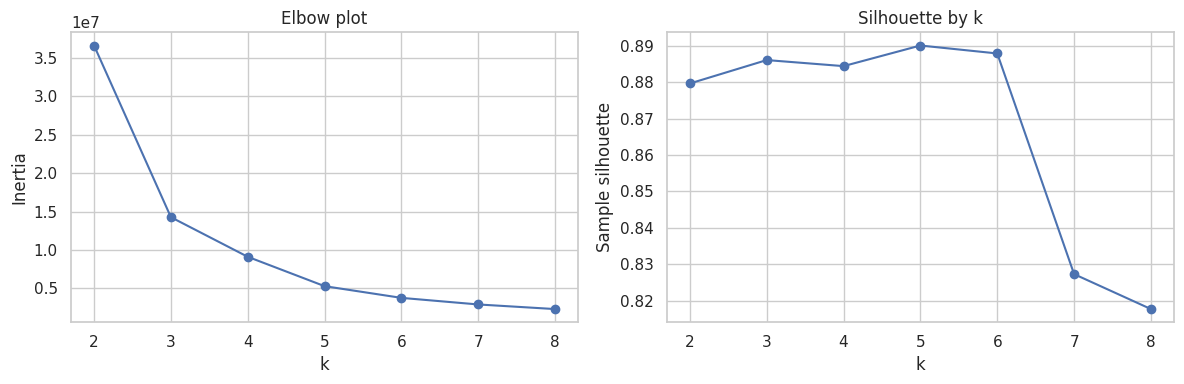

,k,inertia,silhouette_sample
0,2,3.662012e+07,0.879686
1,3,1.427575e+07,0.886121
2,4,9.121636e+06,0.884457
3,5,5.299138e+06,0.890124
4,6,3.775113e+06,0.887938
5,7,2.917336e+06,0.827264
6,8,2.317896e+06,0.817658


In [15]:
ks = range(2, 9)
inertias, silhouettes = [], []
for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10, max_iter=300)
    labels = km.fit_predict(Xz)
    inertias.append(km.inertia_)
    sil = silhouette_score(Xz, labels, sample_size=min(5000, Xz.shape[0]), random_state=42)
    silhouettes.append(sil)
fig, ax = plt.subplots(1,2,figsize=(12,4))
ax[0].plot(list(ks), inertias, marker="o"); ax[0].set(title="Elbow plot", xlabel="k", ylabel="Inertia")
ax[1].plot(list(ks), silhouettes, marker="o"); ax[1].set(title="Silhouette by k", xlabel="k", ylabel="Sample silhouette")
plt.tight_layout(); plt.show()
display(pd.DataFrame({"k":list(ks),"inertia":inertias,"silhouette_sample":silhouettes}))


## 3. Fit K-Means and assess segments

In [16]:
# Fit KMeans with the selected optimal k (e.g., k=5)
optimal_k = 5
km_final = KMeans(n_clusters=optimal_k, random_state=42, n_init=10, max_iter=300)
cluster_id = km_final.fit_predict(Xz)

eval_idx = np.random.default_rng(42).choice(Xz.shape[0], size=min(5000, Xz.shape[0]), replace=False)
Z_eval = Xz[eval_idx].toarray() if hasattr(Xz, "toarray") else Xz[eval_idx]
labels_eval = cluster_id[eval_idx]
print("Sample silhouette:", round(silhouette_score(Z_eval, labels_eval), 4))
print("Sample Davies-Bouldin (lower is better):", round(davies_bouldin_score(Z_eval, labels_eval), 4))
print("Sample Calinski-Harabasz (higher is generally better):", round(calinski_harabasz_score(Z_eval, labels_eval), 2))
seg["Cluster"] = cluster_id
display(seg["Cluster"].value_counts().sort_index().to_frame("customers"))

Sample silhouette: 0.888
Sample Davies-Bouldin (lower is better): 0.3404
Sample Calinski-Harabasz (higher is generally better): 24776.67


,customers
Cluster,
0,39362
1,207
2,1343
3,2182
4,2117


## 4. PCA visualization and cluster interpretation

PCA compresses the transformed feature matrix to two dimensions for a plot. The K-Means fit itself uses the full encoded and scaled feature space. Cluster numbers are arbitrary identifiers; name segments only after reading the profile table.


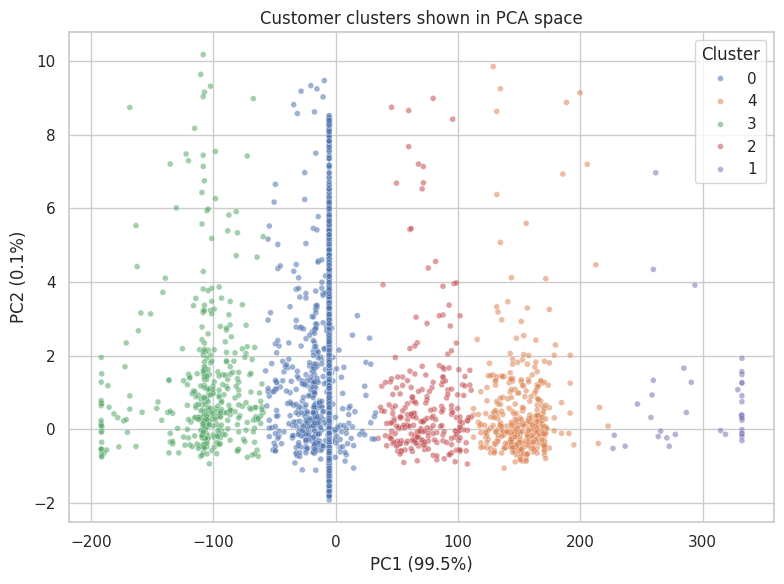

Variance explained by PC1 + PC2: 0.996


In [17]:
# PCA supports sparse matrices; convert only when practical
X_dense = Xz.toarray() if hasattr(Xz, "toarray") else Xz
pca = PCA(n_components=2, random_state=42)
xy = pca.fit_transform(X_dense)
pca_df = pd.DataFrame({"PC1":xy[:,0],"PC2":xy[:,1],"Cluster":cluster_id.astype(str)})
plt.figure(figsize=(8,6))
sns.scatterplot(data=pca_df.sample(min(8000, len(pca_df)), random_state=42),
                x="PC1", y="PC2", hue="Cluster", alpha=.55, s=18)
plt.title("Customer clusters shown in PCA space")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
plt.tight_layout(); plt.show()
print("Variance explained by PC1 + PC2:", round(pca.explained_variance_ratio_.sum(), 3))


In [18]:
profile = seg.groupby("Cluster").agg(
    customers=("y","size"),
    mean_age=("age","mean"),
    median_balance=("balance","median"),
    mean_campaign_contacts=("campaign","mean"),
    prior_contact_share=("previously_contacted","mean"),
    subscription_rate_posthoc=("y", lambda s: (s=="yes").mean())
).round(3)
display(profile)
for col in ["job","education","housing","loan","poutcome","month"]:
    print("\\nTop category by cluster:", col)
    display(seg.groupby("Cluster")[col].agg(lambda s: s.value_counts().index[0]).to_frame("most_common"))


,customers,mean_age,median_balance,mean_campaign_contacts,prior_contact_share,subscription_rate_posthoc
Cluster,,,,,,
0,39362,41.028,432.0,2.870,0.061,0.102
1,207,40.763,816.0,1.763,1.000,0.473
2,1343,40.328,464.0,2.124,1.000,0.127
3,2182,42.074,907.0,1.866,1.000,0.354
4,2117,38.459,366.0,2.214,1.000,0.105


\nTop category by cluster: job


,most_common
Cluster,
0,blue-collar
1,management
2,blue-collar
3,management
4,blue-collar


\nTop category by cluster: education


,most_common
Cluster,
0,secondary
1,secondary
2,secondary
3,secondary
4,secondary


\nTop category by cluster: housing


... (3 outputs left out)

\nTop category by cluster: poutcome


,most_common
Cluster,
0,unknown
1,failure
2,failure
3,failure
4,failure


\nTop category by cluster: month


,most_common
Cluster,
0,may
1,sep
2,may
3,nov
4,may


## 5. Business interpretation and limitations

The profile table can describe segments such as younger/older customers, low/high balance groups, or customers with different campaign histories. Do not name the clusters before reviewing the output. Post-hoc subscription rates can be compared to understand how existing outcomes varied by segment, but `y` was not a clustering input and the rate differences are not causal.

K-Means favours compact, roughly spherical clusters and uses Euclidean geometry. One-hot encoding can create high-dimensional sparse data. The result may depend on k, feature choices, scaling and outlier treatment. Future work can compare MiniBatchKMeans for scale, hierarchical clustering on a sample, Gower distances for mixed data, and cluster stability over resampled datasets.


In [19]:
seg.to_csv("bank_customer_clusters.csv", index=False)
profile.to_csv("bank_cluster_profiles.csv")
print("Saved bank_customer_clusters.csv and bank_cluster_profiles.csv")


Saved bank_customer_clusters.csv and bank_cluster_profiles.csv
